# Smart City Traffic Analytics and Congestion Prediction

### Data Processing Assignment

## A. Dataset Introduction and Workflow Architecture

### A1.1 Introduction to Smart City Traffic Analytics and Congestion Prediction Dataset

Traffic congestion is a major challenge in urban areas due to increasing vehicle usage, population growth and limited road infrastructure. It results in longer travel times, increased fuel consumption and environmental pollution. Analysing traffic data can help identify traffic patterns and support better transportation planning.

For this project, the **Metro Interstate Traffic Volume dataset** from the UCI Machine Learning Repository was selected. The dataset contains hourly traffic volume observations collected from a westbound traffic monitoring station on Interstate 94 in the Minneapolis–St Paul metropolitan area, USA.

The dataset contains 48,204 observations originally, covering the period from 2012 to 2018. It consists of eight input attributes and one target variable, `traffic_volume`.

**Dataset attributes:**

| Attribute | Description |
|---|---|
| holiday | Holiday information |
| temp | Temperature in Kelvin |
| rain_1h | Rainfall recorded in the previous hour |
| snow_1h | Snowfall recorded in the previous hour |
| clouds_all | Cloud coverage percentage |
| weather_main | Main weather condition |
| weather_description | Detailed weather description |
| date_time | Date and time of observation |
| traffic_volume | Number of vehicles recorded |

The target variable, `traffic_volume`, represents the number of vehicles recorded during each hour. The remaining attributes provide information about weather conditions, holidays and observation time.

**Dataset quality assessment**

The dataset was examined to identify missing values, duplicate records, suspicious values and inconsistencies before model development.

- The `holiday` attribute contained 48,143 missing values. These were replaced with the category "No Holiday" based on the assumption that missing entries represented observations without a recorded holiday.
- A total of 17 duplicate records were identified and removed.
- Ten observations contained a temperature value of 0 Kelvin, which was considered physically implausible and treated as missing.
- One unusually high rainfall reading of 9831.3 was identified and treated as a suspected anomalous value.
- No statistical outliers were detected in `traffic_volume` using the 1.5 × IQR rule.

After cleaning, the dataset contained 48,187 observations and 9 original attributes. Missing values and exact duplicate records were handled during preprocessing. Repeated timestamps with differing observations were retained for further analysis.

The selected dataset provides a foundation for analysing the relationship between traffic volume, time-based patterns and weather conditions. However, it represents only one monitoring station and therefore does not directly represent an entire city's road network.

### A1.2 Workflow Architecture and Data Preprocessing

The proposed system follows a structured data-processing workflow to transform raw traffic data into meaningful insights and traffic volume predictions.

**Workflow stages**

1. **Data collection:** The Metro Interstate Traffic Volume dataset was obtained from the UCI Machine Learning Repository.
2. **Data inspection:** The dataset was examined using Pandas to understand its structure, attributes, data types, missing values and duplicate records.
3. **Data cleaning:** Missing values, duplicate records and suspicious observations were handled using appropriate preprocessing techniques.
4. **Feature engineering:** The date and time attribute was converted into a datetime format. Additional features such as hour, day, month, year, day of the week and weekend indicator were extracted.
5. **Exploratory Data Analysis:** Statistical summaries, visualisations and correlation analysis were used to identify traffic patterns and relationships between variables.
6. **Feature encoding:** Categorical variables were converted into numerical representations using One-Hot Encoding.
7. **Data splitting:** The dataset was divided chronologically into 80% training data and 20% testing data.
8. **Model development:** A Random Forest Regressor was trained using the processed training data.
9. **Model evaluation:** Predictions were evaluated using MAE, MSE, RMSE and R² and compared against a baseline model.
10. **Visualisation and interpretation:** Graphs, feature importance and prediction error analysis were used to interpret the results.

The workflow integrates data collection, preprocessing, analysis, machine learning and evaluation to develop a traffic volume prediction system.

Figure 1: Workflow architecture of the proposed traffic analytics and prediction system.

```mermaid
flowchart TD
    A["UCI Traffic Dataset"] --> B["Data Inspection"]
    B --> C["Data Quality Assessment"]
    C --> D["Data Cleaning"]
    D --> E["Feature Engineering"]
    E --> F["Exploratory Data Analysis"]
    F --> G["One-Hot Encoding"]
    G --> H["Chronological Train-Test Split"]
    H --> I["Random Forest Regressor"]
    I --> J["Traffic Volume Prediction"]
    J --> K["Model Evaluation"]
    K --> L["Visualisation and Result Analysis"]
```

In [1]:
import sys
print(sys.version)

import pandas as pd
print(pd.__version__)

import numpy as np
print(np.__version__)

3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
2.1.2
1.25.1


In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
metro_interstate_traffic_volume = fetch_ucirepo(id=492) 
  
# data (as pandas dataframes) 
X = metro_interstate_traffic_volume.data.features 
y = metro_interstate_traffic_volume.data.targets 
  
# metadata 
print(metro_interstate_traffic_volume.metadata) 
  
# variable information 
print(metro_interstate_traffic_volume.variables) 


{'uci_id': 492, 'name': 'Metro Interstate Traffic Volume', 'repository_url': 'https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume', 'data_url': 'https://archive.ics.uci.edu/static/public/492/data.csv', 'abstract': 'Hourly Minneapolis-St Paul, MN traffic volume for westbound I-94. Includes weather and holiday features from 2012-2018.', 'area': 'Other', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 48204, 'num_features': 8, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['traffic_volume'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2019, 'last_updated': 'Fri Mar 15 2024', 'dataset_doi': '10.24432/C5X60B', 'creators': ['John Hogue'], 'intro_paper': None, 'additional_info': {'summary': 'Hourly Interstate 94 Westbound traffic volume for MN DoT ATR station 301, roughly midway between Minneapolis and St Paul, MN. Hourly weath

In [3]:
print(X.shape)
print(y.shape)
print(X.head())

(48204, 8)
(48204, 1)
  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description            date_time  
0    scattered clouds  2012-10-02 09:00:00  
1       broken clouds  2012-10-02 10:00:00  
2     overcast clouds  2012-10-02 11:00:00  
3     overcast clouds  2012-10-02 12:00:00  
4       broken clouds  2012-10-02 13:00:00  


In [4]:
print(X.isnull().sum())

holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
dtype: int64


In [5]:
print(X["holiday"].value_counts(dropna=False))

holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [6]:
print(X.dtypes)

holiday                 object
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main            object
weather_description     object
date_time               object
dtype: object


In [7]:
print(X.duplicated().sum())

17


In [8]:
df = metro_interstate_traffic_volume.data.original.copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [9]:
print(df.duplicated().sum())

17


In [10]:
df[df.duplicated(keep=False)].head(10)

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
18696,NaN,286.290,0.0,0.0,1,Clear,sky is clear,2015-09-30 19:00:00,3679
18697,NaN,286.290,0.0,0.0,1,Clear,sky is clear,2015-09-30 19:00:00,3679
23850,NaN,289.060,0.0,0.0,90,Clouds,overcast clouds,2016-06-01 10:00:00,4831
23851,NaN,289.060,0.0,0.0,90,Clouds,overcast clouds,2016-06-01 10:00:00,4831
26783,NaN,289.775,0.0,0.0,56,Clouds,broken clouds,2016-09-21 15:00:00,5365
26784,NaN,289.775,0.0,0.0,56,Clouds,broken clouds,2016-09-21 15:00:00,5365
26979,NaN,287.860,0.0,0.0,0,Clear,Sky is Clear,2016-09-29 19:00:00,3435
26980,NaN,287.860,0.0,0.0,0,Clear,Sky is Clear,2016-09-29 19:00:00,3435
27170,NaN,279.287,0.0,0.0,56,Clouds,broken clouds,2016-10-07 18:00:00,4642
27171,NaN,279.287,0.0,0.0,56,Clouds,broken clouds,2016-10-07 18:00:00,4642


In [11]:
df = df.drop_duplicates()

In [12]:
print(df.duplicated().sum())
print(df.shape)

0
(48187, 9)


In [13]:
print(df["holiday"].isnull().sum())
print(df["holiday"].value_counts())

48126
holiday
Labor Day                    7
Thanksgiving Day             6
Christmas Day                6
New Years Day                6
Martin Luther King Jr Day    6
Columbus Day                 5
Veterans Day                 5
Washingtons Birthday         5
Memorial Day                 5
Independence Day             5
State Fair                   5
Name: count, dtype: int64


In [14]:
print(df["holiday"].isnull().mean() * 100)

99.87340984082844


### Handling Missing Values in the Holiday Column

The holiday column contains 48,143 missing values. Since the dataset records traffic observations for ordinary days as well as holidays, missing entries are treated as "No Holiday" for this analysis. This is an assumption made during preprocessing and may introduce some classification uncertainty.

In [15]:
df["holiday"] = df["holiday"].fillna("No Holiday")

In [16]:
print(df["holiday"].isnull().sum())

0


In [17]:
print(df["traffic_volume"].describe())

count    48187.000000
mean      3259.618134
std       1986.954465
min          0.000000
25%       1192.500000
50%       3379.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64


In [18]:
Q1 = df["traffic_volume"].quantile(0.25)
Q3 = df["traffic_volume"].quantile(0.75)
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 1192.5
Q3: 4933.0


In [19]:
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

IQR: 3740.5
Lower Bound: -4418.25
Upper Bound: 10543.75


In [20]:
outliers = df[
    (df["traffic_volume"] < lower_bound) |
    (df["traffic_volume"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 0


In [21]:
print(df[["temp", "rain_1h", "snow_1h", "clouds_all"]].describe())

               temp       rain_1h       snow_1h    clouds_all
count  48187.000000  48187.000000  48187.000000  48187.000000
mean     281.204995      0.334382      0.000222     49.365451
std       13.338738     44.797033      0.008169     39.015213
min        0.000000      0.000000      0.000000      0.000000
25%      272.160000      0.000000      0.000000      1.000000
50%      282.450000      0.000000      0.000000     64.000000
75%      291.806000      0.000000      0.000000     90.000000
max      310.070000   9831.300000      0.510000    100.000000


In [22]:
print("Rows where temperature is 0:")
display(df[df["temp"] == 0])

print("\n10 records with the highest rainfall:")
display(df.nlargest(10, "rain_1h")[["date_time", "temp", "rain_1h", "snow_1h", "traffic_volume"]])

Rows where temperature is 0:


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11898,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 03:00:00,361
11899,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 04:00:00,734
11900,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 05:00:00,2557
11901,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 06:00:00,5150
11946,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 03:00:00,291
11947,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 04:00:00,284
11948,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 05:00:00,434
11949,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 06:00:00,739
11950,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 07:00:00,962
11951,No Holiday,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 08:00:00,1670



10 records with the highest rainfall:


,date_time,temp,rain_1h,snow_1h,traffic_volume
24872,2016-07-11 17:00:00,302.11,9831.30,0.0,5535
8247,2013-08-07 02:00:00,289.10,55.63,0.0,315
7179,2013-06-24 11:00:00,295.82,44.45,0.0,4802
25779,2016-08-16 17:00:00,297.71,31.75,0.0,4913
10806,2013-12-19 23:00:00,264.50,28.70,0.0,1190
10807,2013-12-19 23:00:00,264.50,28.70,0.0,1190
16504,2015-07-13 00:00:00,292.02,27.57,0.0,492
16505,2015-07-13 00:00:00,292.02,27.57,0.0,492
16506,2015-07-13 00:00:00,292.02,27.57,0.0,492
17437,2015-08-16 21:00:00,294.49,25.46,0.0,2118


In [23]:
print("Zero temperature records:", (df["temp"] == 0).sum())

print("Rainfall above 100 mm:",
      (df["rain_1h"] > 100).sum())

print("Duplicate rows:", df.duplicated().sum())

Zero temperature records: 10
Rainfall above 100 mm: 1
Duplicate rows: 0


In [24]:
display(df[df["rain_1h"] > 100])

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
24872,No Holiday,302.11,9831.3,0.0,75,Rain,very heavy rain,2016-07-11 17:00:00,5535


In [25]:
print(df["rain_1h"].sort_values(ascending=False).head(15))

24872    9831.30
8247       55.63
7179       44.45
25779      31.75
10806      28.70
10807      28.70
16504      27.57
16505      27.57
16506      27.57
17439      25.46
17437      25.46
17438      25.46
7668       25.32
7667       25.32
7669       25.32
Name: rain_1h, dtype: float64


In [26]:
zero_temp = df[df["temp"] == 0]

display(zero_temp[[
    "date_time",
    "temp",
    "weather_main",
    "weather_description",
    "traffic_volume"
]])

,date_time,temp,weather_main,weather_description,traffic_volume
11898,2014-01-31 03:00:00,0.0,Clear,sky is clear,361
11899,2014-01-31 04:00:00,0.0,Clear,sky is clear,734
11900,2014-01-31 05:00:00,0.0,Clear,sky is clear,2557
11901,2014-01-31 06:00:00,0.0,Clear,sky is clear,5150
11946,2014-02-02 03:00:00,0.0,Clear,sky is clear,291
11947,2014-02-02 04:00:00,0.0,Clear,sky is clear,284
11948,2014-02-02 05:00:00,0.0,Clear,sky is clear,434
11949,2014-02-02 06:00:00,0.0,Clear,sky is clear,739
11950,2014-02-02 07:00:00,0.0,Clear,sky is clear,962
11951,2014-02-02 08:00:00,0.0,Clear,sky is clear,1670


### Handling Anomalies in Temperature and Rainfall

Exploratory analysis identified 10 records with a temperature of 0 K, which is physically implausible for the recorded weather conditions. These values were treated as invalid observations and replaced with the median temperature of 282.46 K.

One extreme rainfall value of 9831.3 mm was also identified, which is highly unusual compared with the other observations. Since its validity could not be independently confirmed, it was treated as a suspected anomaly and replaced with the median rainfall value of 0 mm.

Median imputation was selected because it is less sensitive to extreme values than mean imputation.

In [27]:
df_clean = df.copy()

df_clean.loc[df_clean["temp"] == 0, "temp"] = float("nan")

print("Missing temperature values:",
      df_clean["temp"].isnull().sum())

Missing temperature values: 10


In [28]:
median_temp = df_clean["temp"].median()

print("Median temperature:", median_temp)

Median temperature: 282.46


In [29]:
df_clean["temp"] = df_clean["temp"].fillna(median_temp)

print("Remaining missing temperatures:",
      df_clean["temp"].isnull().sum())

Remaining missing temperatures: 0


In [30]:
df_clean.loc[df_clean["rain_1h"] > 100, "rain_1h"] = float("nan")

print("Missing rainfall values:",
      df_clean["rain_1h"].isnull().sum())

Missing rainfall values: 1


In [31]:
median_rain = df_clean["rain_1h"].median()

print("Median rainfall:", median_rain)

Median rainfall: 0.0


In [32]:
df_clean["rain_1h"] = df_clean["rain_1h"].fillna(median_rain)

print("Remaining missing rainfall values:",
      df_clean["rain_1h"].isnull().sum())

Remaining missing rainfall values: 0


In [33]:
print(df_clean.isnull().sum())

holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64


In [34]:
df_clean["date_time"] = pd.to_datetime(df_clean["date_time"])

print(df_clean["date_time"].dtype)

datetime64[ns]


In [35]:
df_clean["hour"] = df_clean["date_time"].dt.hour

print(df_clean[["date_time", "hour"]].head(10))

            date_time  hour
0 2012-10-02 09:00:00     9
1 2012-10-02 10:00:00    10
2 2012-10-02 11:00:00    11
3 2012-10-02 12:00:00    12
4 2012-10-02 13:00:00    13
5 2012-10-02 14:00:00    14
6 2012-10-02 15:00:00    15
7 2012-10-02 16:00:00    16
8 2012-10-02 17:00:00    17
9 2012-10-02 18:00:00    18


### Temporal Feature Engineering

The date_time column was used to extract meaningful time-based features, including hour, day, month, year and day of the week. A binary is_weekend feature was also created, where 1 represents Saturday or Sunday and 0 represents weekdays.

These features help the model identify recurring temporal patterns in traffic volume.

In [36]:
df_clean["day"] = df_clean["date_time"].dt.day
df_clean["month"] = df_clean["date_time"].dt.month
df_clean["year"] = df_clean["date_time"].dt.year

print(df_clean[["date_time", "hour", "day", "month", "year"]].head(10))

            date_time  hour  day  month  year
0 2012-10-02 09:00:00     9    2     10  2012
1 2012-10-02 10:00:00    10    2     10  2012
2 2012-10-02 11:00:00    11    2     10  2012
3 2012-10-02 12:00:00    12    2     10  2012
4 2012-10-02 13:00:00    13    2     10  2012
5 2012-10-02 14:00:00    14    2     10  2012
6 2012-10-02 15:00:00    15    2     10  2012
7 2012-10-02 16:00:00    16    2     10  2012
8 2012-10-02 17:00:00    17    2     10  2012
9 2012-10-02 18:00:00    18    2     10  2012


In [37]:
df_clean["day_of_week"] = df_clean["date_time"].dt.dayofweek

print(df_clean[["date_time", "day_of_week"]].head(10))

            date_time  day_of_week
0 2012-10-02 09:00:00            1
1 2012-10-02 10:00:00            1
2 2012-10-02 11:00:00            1
3 2012-10-02 12:00:00            1
4 2012-10-02 13:00:00            1
5 2012-10-02 14:00:00            1
6 2012-10-02 15:00:00            1
7 2012-10-02 16:00:00            1
8 2012-10-02 17:00:00            1
9 2012-10-02 18:00:00            1


In [38]:
df_clean["is_weekend"] = df_clean["day_of_week"].isin([5, 6]).astype(int)

print(df_clean[["date_time", "day_of_week", "is_weekend"]].head(10))

            date_time  day_of_week  is_weekend
0 2012-10-02 09:00:00            1           0
1 2012-10-02 10:00:00            1           0
2 2012-10-02 11:00:00            1           0
3 2012-10-02 12:00:00            1           0
4 2012-10-02 13:00:00            1           0
5 2012-10-02 14:00:00            1           0
6 2012-10-02 15:00:00            1           0
7 2012-10-02 16:00:00            1           0
8 2012-10-02 17:00:00            1           0
9 2012-10-02 18:00:00            1           0


In [39]:
print("Dataset shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

display(df_clean.head())

Dataset shape: (48187, 15)

Columns:
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume', 'hour', 'day', 'month', 'year', 'day_of_week', 'is_weekend']


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,day,month,year,day_of_week,is_weekend
0,No Holiday,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,2,10,2012,1,0
1,No Holiday,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,2,10,2012,1,0
2,No Holiday,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,2,10,2012,1,0
3,No Holiday,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,2,10,2012,1,0
4,No Holiday,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,2,10,2012,1,0


### Exploratory Data Analysis: Temporal Traffic Patterns

Exploratory analysis was performed to understand how traffic volume changes over time. Average traffic volume was calculated for each hour of the day, and weekday traffic was compared with weekend traffic.

The analysis helps identify recurring traffic patterns and provides insights into peak traffic periods and differences between working days and weekends.

In [40]:
hourly_traffic = df_clean.groupby("hour")["traffic_volume"].mean()

print(hourly_traffic)

hour
0      834.984774
1      516.339033
2      388.353640
3      371.090864
4      702.551889
5     2094.573437
6     4140.503594
7     4740.181337
8     4587.497115
9     4385.277502
10    4184.135838
11    4465.569231
12    4718.031730
13    4714.652836
14    4931.888776
15    5240.459907
16    5663.756539
17    5310.076048
18    4263.563792
19    3275.206438
20    2834.667509
21    2668.940464
22    2199.405717
23    1469.135294
Name: traffic_volume, dtype: float64


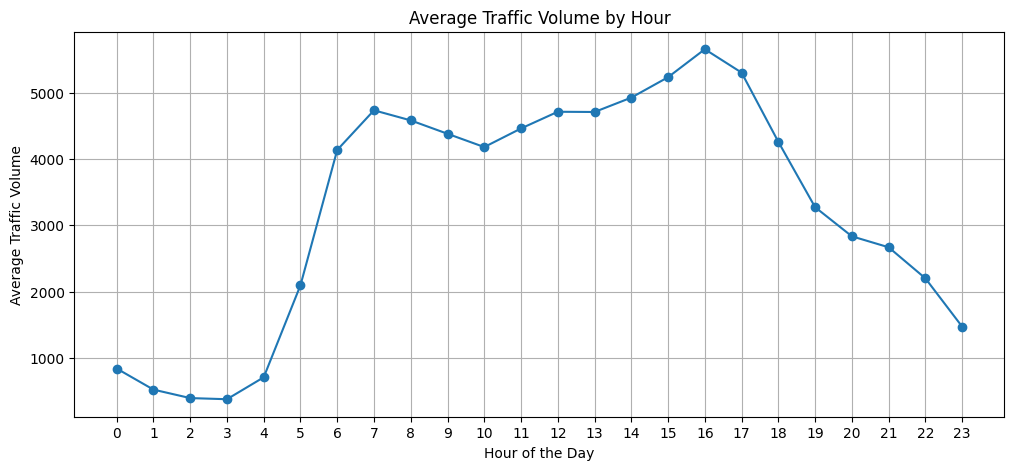

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(hourly_traffic.index, hourly_traffic.values, marker="o")

plt.title("Average Traffic Volume by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Traffic Volume")

plt.xticks(range(24))
plt.grid(True)

plt.show()

In [42]:
weekend_traffic = df_clean.groupby("is_weekend")["traffic_volume"].mean()

print(weekend_traffic)

is_weekend
0    3533.291791
1    2570.699635
Name: traffic_volume, dtype: float64


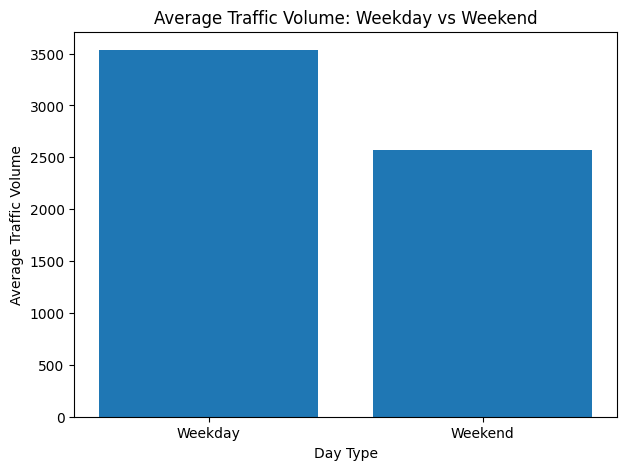

In [43]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Weekday", "Weekend"],
    weekend_traffic.values
)

plt.title("Average Traffic Volume: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Traffic Volume")

plt.show()

In [44]:
daily_traffic = df_clean.groupby("day_of_week")["traffic_volume"].mean()

print(daily_traffic)

day_of_week
0    3309.795786
1    3488.339714
2    3582.568582
3    3637.929431
4    3655.325622
5    2773.485212
6    2369.094760
Name: traffic_volume, dtype: float64


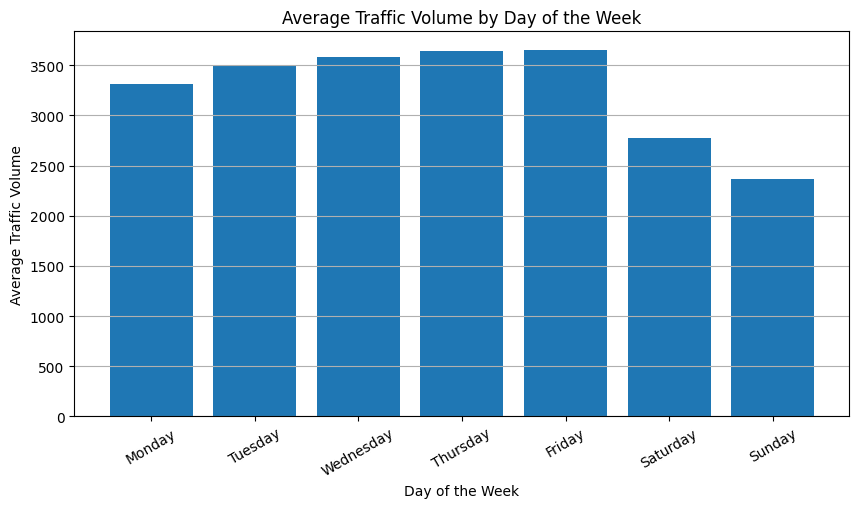

In [45]:
days = ["Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(10, 5))

plt.bar(days, daily_traffic.values)

plt.title("Average Traffic Volume by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Traffic Volume")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

### Monthly and Weather-Based Traffic Analysis

Average traffic volume was grouped by month to examine seasonal variations. Traffic volume was also grouped by the main weather condition to explore possible associations between weather and traffic patterns.

These comparisons help identify patterns in the dataset. However, differences in average traffic do not establish that a particular month or weather condition directly causes changes in traffic volume.

In [46]:
monthly_traffic = df_clean.groupby("month")["traffic_volume"].mean()

print(monthly_traffic)

month
1     3051.081378
2     3197.945547
3     3308.388611
4     3304.372388
5     3366.319432
6     3416.693043
7     3205.481752
8     3394.241891
9     3301.930737
10    3390.317972
11    3168.970955
12    3024.304286
Name: traffic_volume, dtype: float64


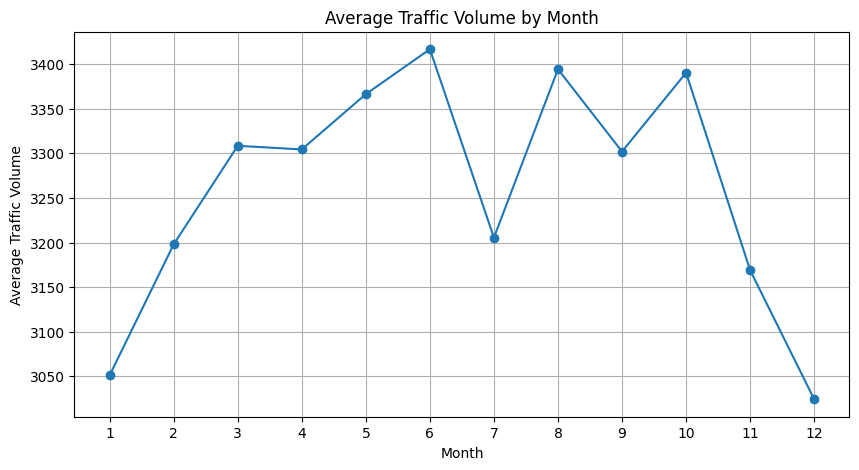

In [47]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_traffic.index, monthly_traffic.values, marker="o")

plt.title("Average Traffic Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average Traffic Volume")

plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [48]:
weather_traffic = df_clean.groupby("weather_main")["traffic_volume"].mean().sort_values(ascending=False)

print(weather_traffic)

weather_main
Clouds          3617.989115
Haze            3502.101471
Rain            3317.905501
Drizzle         3292.189560
Smoke           3237.650000
Clear           3055.614465
Snow            3016.321391
Thunderstorm    2999.431752
Mist            2933.343923
Fog             2703.720395
Squall          2061.750000
Name: traffic_volume, dtype: float64


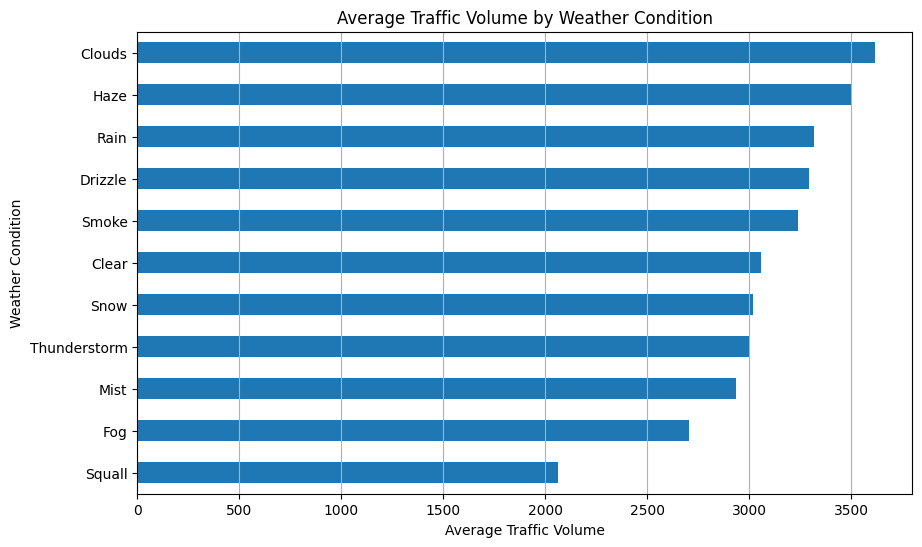

In [49]:
plt.figure(figsize=(10, 6))

weather_traffic.sort_values().plot(kind="barh")

plt.title("Average Traffic Volume by Weather Condition")
plt.xlabel("Average Traffic Volume")
plt.ylabel("Weather Condition")

plt.grid(axis="x")
plt.show()

### Correlation and Traffic Volume Distribution

Correlation analysis was performed to examine the linear relationships between numerical weather variables and traffic volume. A correlation heatmap was generated to visualise these relationships.

Yearly average traffic volume was also analysed to observe changes over time. Finally, a histogram was plotted to understand the distribution and frequency of traffic-volume observations.

In [50]:
numeric_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

correlation = df_clean[numeric_columns].corr()

print(correlation["traffic_volume"].sort_values(ascending=False))

traffic_volume    1.000000
temp              0.132108
clouds_all        0.067138
snow_1h           0.000736
rain_1h          -0.022345
Name: traffic_volume, dtype: float64


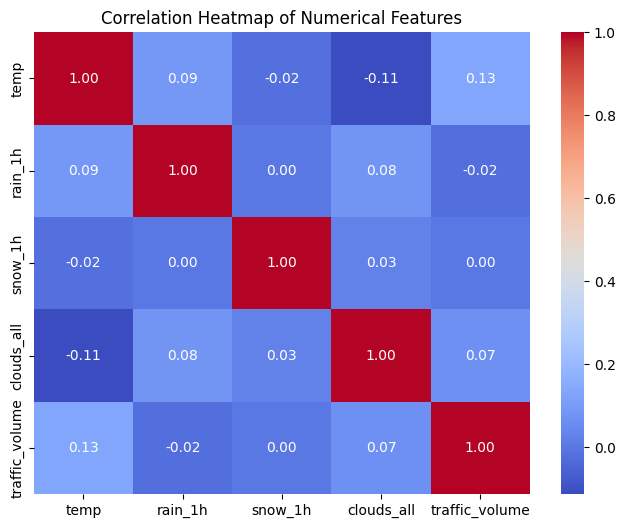

In [51]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [52]:
yearly_traffic = df_clean.groupby("year")["traffic_volume"].mean()

print(yearly_traffic)

year
2012    3207.802657
2013    3286.762160
2014    3250.938004
2015    3242.801235
2016    3168.990108
2017    3340.298320
2018    3260.042149
Name: traffic_volume, dtype: float64


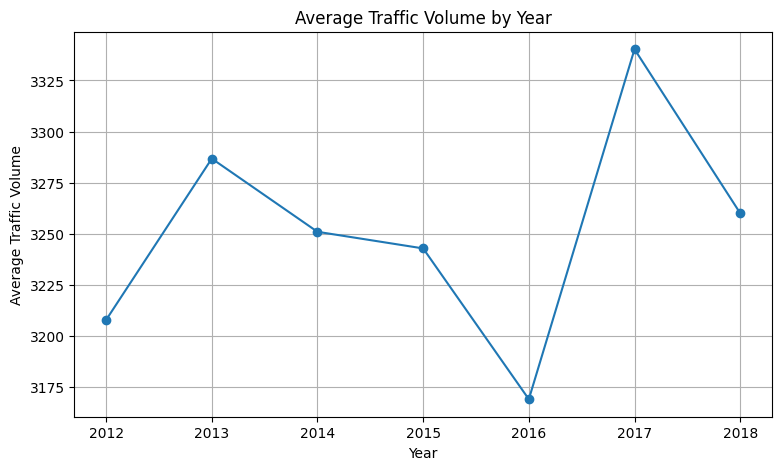

In [53]:
plt.figure(figsize=(9, 5))

plt.plot(yearly_traffic.index, yearly_traffic.values, marker="o")

plt.title("Average Traffic Volume by Year")
plt.xlabel("Year")
plt.ylabel("Average Traffic Volume")

plt.xticks(yearly_traffic.index)
plt.grid(True)

plt.show()

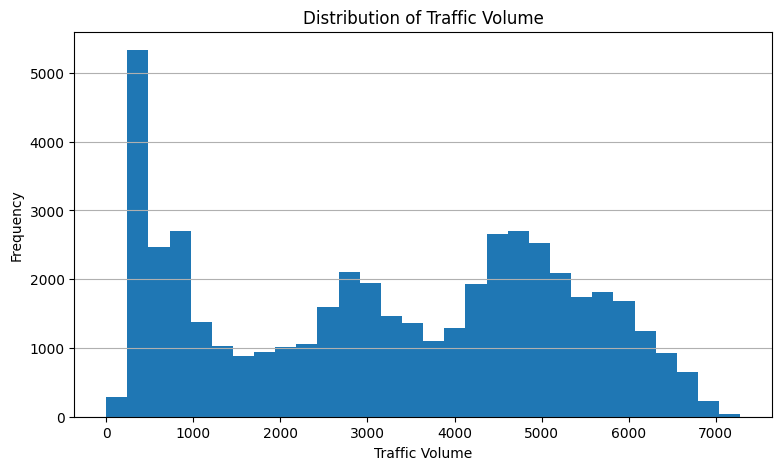

In [54]:
plt.figure(figsize=(9, 5))

plt.hist(df_clean["traffic_volume"], bins=30)

plt.title("Distribution of Traffic Volume")
plt.xlabel("Traffic Volume")
plt.ylabel("Frequency")

plt.grid(axis="y")
plt.show()

In [55]:
print(df_clean.columns.tolist())

['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume', 'hour', 'day', 'month', 'year', 'day_of_week', 'is_weekend']


### Feature and Target Selection

The cleaned dataset was divided into input features and a target variable for supervised machine learning.

The input features include weather conditions, holiday information and temporal attributes such as hour, day, month, year and day of the week.

The target variable is traffic_volume, which represents the observed traffic volume that the model aims to predict.

In [56]:
features = [
    "holiday",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "weather_main",
    "hour",
    "day",
    "month",
    "year",
    "day_of_week",
    "is_weekend"
]

X = df_clean[features]

print(X.head())
print("Feature shape:", X.shape)

      holiday    temp  rain_1h  snow_1h  clouds_all weather_main  hour  day  \
0  No Holiday  288.28      0.0      0.0          40       Clouds     9    2   
1  No Holiday  289.36      0.0      0.0          75       Clouds    10    2   
2  No Holiday  289.58      0.0      0.0          90       Clouds    11    2   
3  No Holiday  290.13      0.0      0.0          90       Clouds    12    2   
4  No Holiday  291.14      0.0      0.0          75       Clouds    13    2   

   month  year  day_of_week  is_weekend  
0     10  2012            1           0  
1     10  2012            1           0  
2     10  2012            1           0  
3     10  2012            1           0  
4     10  2012            1           0  
Feature shape: (48187, 12)


In [57]:
y = df_clean["traffic_volume"]

print(y.head())
print("Target shape:", y.shape)

0    5545
1    4516
2    4767
3    5026
4    4918
Name: traffic_volume, dtype: int64
Target shape: (48187,)


In [58]:
print("Holiday categories:")
print(X["holiday"].unique())

print("\nWeather categories:")
print(X["weather_main"].unique())

Holiday categories:
['No Holiday' 'Columbus Day' 'Veterans Day' 'Thanksgiving Day'
 'Christmas Day' 'New Years Day' 'Washingtons Birthday' 'Memorial Day'
 'Independence Day' 'State Fair' 'Labor Day' 'Martin Luther King Jr Day']

Weather categories:
['Clouds' 'Clear' 'Rain' 'Drizzle' 'Mist' 'Haze' 'Fog' 'Thunderstorm'
 'Snow' 'Squall' 'Smoke']


In [59]:
print(X["holiday"].value_counts())

print("\nWeather category counts:")
print(X["weather_main"].value_counts())

holiday
No Holiday                   48126
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64

Weather category counts:
weather_main
Clouds          15158
Clear           13384
Mist             5949
Rain             5672
Snow             2875
Drizzle          1820
Haze             1360
Thunderstorm     1033
Fog               912
Smoke              20
Squall              4
Name: count, dtype: int64


### Train-Test Split and Categorical Encoding

The dataset was divided chronologically into 80% training data and 20% testing data. This approach preserves the time order of observations and allows the model to be evaluated on later traffic records.

Categorical variables, namely holiday and weather_main, were converted into numerical representations using One-Hot Encoding. The encoder was fitted on the training data and then applied to the testing data.

Numerical features were separated for further processing.

In [60]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training period:",
      df_clean["date_time"].iloc[0],
      "to",
      df_clean["date_time"].iloc[split_index - 1])

print("Testing period:",
      df_clean["date_time"].iloc[split_index],
      "to",
      df_clean["date_time"].iloc[-1])

Training data: (38549, 12)
Testing data: (9638, 12)
Training period: 2012-10-02 09:00:00 to 2017-11-01 19:00:00
Testing period: 2017-11-01 20:00:00 to 2018-09-30 23:00:00


In [61]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

In [62]:
categorical_cols = ["holiday", "weather_main"]

X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

print("Training encoded shape:", X_train_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)

Training encoded shape: (38549, 23)
Testing encoded shape: (9638, 23)


In [63]:
numerical_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print(numerical_cols)
print("Number of numerical features:", len(numerical_cols))

['temp', 'rain_1h', 'snow_1h', 'clouds_all', 'hour', 'day', 'month', 'year', 'day_of_week', 'is_weekend']
Number of numerical features: 10


In [64]:
X_train_num = X_train[numerical_cols]
X_test_num = X_test[numerical_cols]

print("Training numerical shape:", X_train_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Training numerical shape: (38549, 10)
Testing numerical shape: (9638, 10)


### Model Preparation and Training

The numerical features and one-hot encoded categorical features were combined to create the final training and testing matrices. The resulting datasets contain 33 input features.

A Random Forest Regressor was selected for traffic-volume prediction. The model was configured with 100 decision trees, a random state of 42 for reproducibility and parallel processing using all available CPU cores.

The model was trained using the training dataset and subsequently used to predict traffic volume for the unseen testing dataset.

In [65]:
from scipy.sparse import hstack

X_train_final = hstack([
    X_train_num.values,
    X_train_encoded
])

X_test_final = hstack([
    X_test_num.values,
    X_test_encoded
])

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (38549, 33)
Final testing shape: (9638, 33)


In [66]:
from sklearn.ensemble import RandomForestRegressor

In [67]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestRegressor(n_jobs=-1, random_state=42)


In [68]:
rf_model.fit(X_train_final, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [69]:
y_pred = rf_model.predict(X_test_final)

print("First 10 predicted values:")
print(y_pred[:10])

First 10 predicted values:
[2485.67 2434.81 2451.85 2434.19 2504.48 1933.35 1941.53 1079.82  602.83
  394.97]


In [70]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})

print(comparison)

   Actual  Predicted
0    2704    2485.67
1    2704    2434.81
2    2704    2451.85
3    2204    2434.19
4    2204    2504.48
5    1713    1933.35
6    1713    1941.53
7    1068    1079.82
8     611     602.83
9     362     394.97


### Model Performance Evaluation

The trained model was evaluated using four regression metrics:

- Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted values.
- Mean Squared Error (MSE): Measures the average squared prediction error.
- Root Mean Squared Error (RMSE): Represents the square root of MSE and expresses prediction error in the original target unit.
- R-squared (R²): Measures the proportion of variance in the target variable explained by the model.

An actual-versus-predicted plot was also generated to visually assess prediction performance.

In [71]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [72]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 283.15838659472917
Mean Squared Error: 239509.3258058622
Root Mean Squared Error: 489.39690007790426
R2 Score: 0.93813440196827


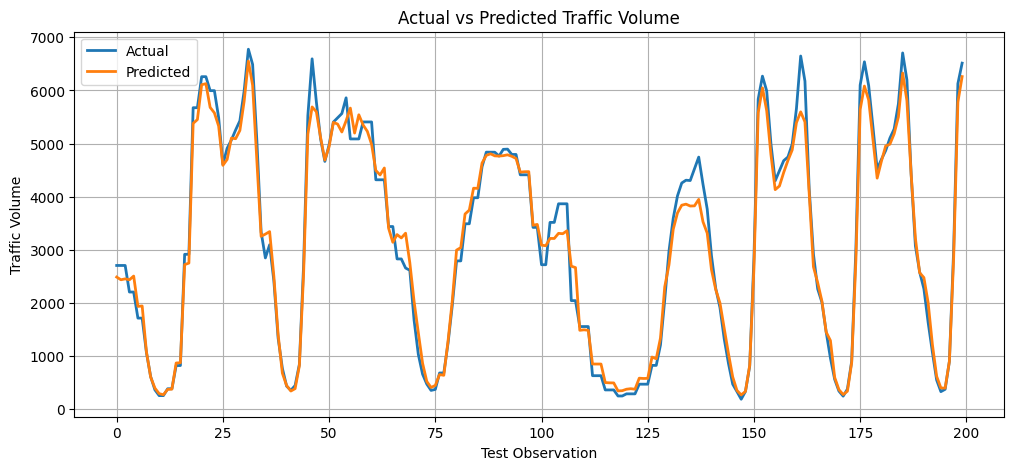

In [73]:
plt.figure(figsize=(12, 5))

plt.plot(y_test.values[:200], label="Actual", linewidth=2)
plt.plot(y_pred[:200], label="Predicted", linewidth=2)

plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Test Observation")
plt.ylabel("Traffic Volume")

plt.legend()
plt.grid(True)
plt.show()

### Feature Importance Analysis

Feature importance was extracted from the trained Random Forest model to identify the input variables that contributed most to its predictions.

The importance scores were sorted in descending order to identify the most influential features. This analysis helps interpret the model and understand which temporal and weather-related variables contribute most to traffic-volume prediction.

In [74]:
feature_names = numerical_cols + list(
    encoder.get_feature_names_out(categorical_cols)
)

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                Feature  Importance
4                  hour    0.828907
8           day_of_week    0.056585
9            is_weekend    0.052667
0                  temp    0.017979
5                   day    0.016965
6                 month    0.011203
7                  year    0.005521
3            clouds_all    0.003562
1               rain_1h    0.002584
23  weather_main_Clouds    0.001210
22   weather_main_Clear    0.000626
27    weather_main_Mist    0.000523
30    weather_main_Snow    0.000420
28    weather_main_Rain    0.000340
26    weather_main_Haze    0.000317


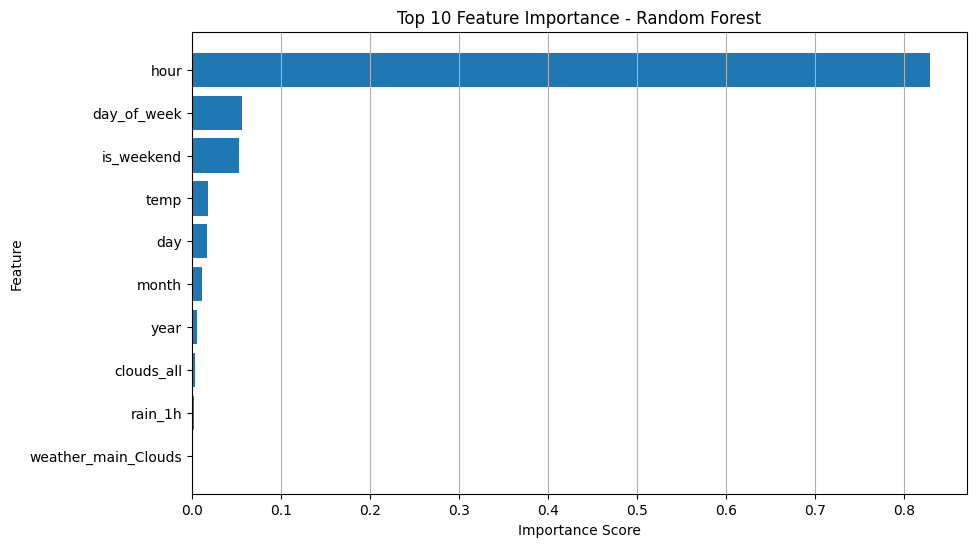

In [75]:
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.grid(axis="x")
plt.show()

### Baseline Model Comparison

To evaluate whether the Random Forest model provides meaningful predictive improvement, a baseline model was developed using Scikit-learn's DummyRegressor with the mean strategy.

The baseline predicts the mean training-set traffic volume for every test observation. Its performance was compared with the Random Forest model using MAE, MSE, RMSE and R-squared.

This comparison helps establish whether the machine learning model performs better than a simple prediction approach.

In [76]:
from sklearn.dummy import DummyRegressor

In [77]:
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train_final, y_train)

baseline_pred = baseline_model.predict(X_test_final)

print("First 10 baseline predictions:")
print(baseline_pred[:10])

First 10 baseline predictions:
[3260.6004825 3260.6004825 3260.6004825 3260.6004825 3260.6004825
 3260.6004825 3260.6004825 3260.6004825 3260.6004825 3260.6004825]


In [78]:
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline MSE:", baseline_mse)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 1722.4961678630655
Baseline MSE: 3871470.1831456413
Baseline RMSE: 1967.605189855333
Baseline R2: -6.230807294338447e-06


In [79]:
results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2"],
    "Baseline": [
        baseline_mae,
        baseline_mse,
        baseline_rmse,
        baseline_r2
    ],
    "Random Forest": [
        mae,
        mse,
        rmse,
        r2
    ]
})

print(results)


  Metric      Baseline  Random Forest
0    MAE  1.722496e+03     283.158387
1    MSE  3.871470e+06  239509.325806
2   RMSE  1.967605e+03     489.396900
3     R2 -6.230807e-06       0.938134


### Prediction Error Analysis

Prediction errors were calculated by subtracting predicted traffic volume from actual traffic volume.

The mean error and maximum and minimum absolute errors were examined to understand the model's prediction behaviour. The observations with the largest absolute errors were also investigated to identify possible patterns or unusual conditions associated with inaccurate predictions.

Repeated timestamps were examined separately to understand the structure of the dataset.

In [80]:
errors = y_test.values - y_pred

print("Mean error:", np.mean(errors))
print("Maximum absolute error:", np.max(np.abs(errors)))
print("Minimum absolute error:", np.min(np.abs(errors)))

Mean error: -57.805927578335755
Maximum absolute error: 4077.05
Minimum absolute error: 0.09000000000003183


In [81]:
error_analysis = pd.DataFrame({
    "Date_Time": df_clean.loc[y_test.index, "date_time"].values,
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Absolute_Error": np.abs(errors)
})

error_analysis = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(error_analysis.head(10))

,Date_Time,Actual,Predicted,Absolute_Error
622,2017-11-23 06:00:00,834,4911.05,4077.05
623,2017-11-23 07:00:00,991,4968.26,3977.26
2310,2018-01-22 16:00:00,1488,5441.12,3953.12
2311,2018-01-22 16:00:00,1488,5433.51,3945.51
949,2017-12-05 07:00:00,2334,6018.44,3684.44
950,2017-12-05 08:00:00,2160,5775.62,3615.62
2312,2018-01-22 17:00:00,1379,4991.21,3612.21
3519,2018-03-05 17:00:00,1953,5521.48,3568.48
2313,2018-01-22 17:00:00,1379,4918.41,3539.41
4694,2018-04-14 16:00:00,1461,4980.04,3519.04


In [82]:
df_clean[
    df_clean["date_time"].isin([
        "2018-01-22 16:00:00",
        "2018-01-22 17:00:00"
    ])
][["date_time", "traffic_volume", "weather_main"]]

,date_time,traffic_volume,weather_main
40875,2018-01-22 16:00:00,1488,Snow
40876,2018-01-22 16:00:00,1488,Fog
40877,2018-01-22 17:00:00,1379,Snow
40878,2018-01-22 17:00:00,1379,Fog


In [83]:
df_clean["date_time"].duplicated().sum()

7612

In [84]:
worst_indices = error_analysis.head(10).index

worst_error_details = error_analysis.head(10).copy()

worst_error_details["Hour"] = X_test.iloc[
    worst_indices
]["hour"].values

worst_error_details["Day_of_Week"] = X_test.iloc[
    worst_indices
]["day_of_week"].values

worst_error_details["Weather"] = X_test.iloc[
    worst_indices
]["weather_main"].values

worst_error_details["Holiday"] = X_test.iloc[
    worst_indices
]["holiday"].values

display(worst_error_details)

,Date_Time,Actual,Predicted,Absolute_Error,Hour,Day_of_Week,Weather,Holiday
622,2017-11-23 06:00:00,834,4911.05,4077.05,6,3,Clear,No Holiday
623,2017-11-23 07:00:00,991,4968.26,3977.26,7,3,Clear,No Holiday
2310,2018-01-22 16:00:00,1488,5441.12,3953.12,16,0,Snow,No Holiday
2311,2018-01-22 16:00:00,1488,5433.51,3945.51,16,0,Fog,No Holiday
949,2017-12-05 07:00:00,2334,6018.44,3684.44,7,1,Clear,No Holiday
950,2017-12-05 08:00:00,2160,5775.62,3615.62,8,1,Snow,No Holiday
2312,2018-01-22 17:00:00,1379,4991.21,3612.21,17,0,Snow,No Holiday
3519,2018-03-05 17:00:00,1953,5521.48,3568.48,17,0,Snow,No Holiday
2313,2018-01-22 17:00:00,1379,4918.41,3539.41,17,0,Fog,No Holiday
4694,2018-04-14 16:00:00,1461,4980.04,3519.04,16,5,Snow,No Holiday


### Further Prediction Error Analysis

Prediction errors were grouped by hour to examine whether the model performs differently during various periods of the day.

The distribution of prediction errors was visualised to understand the spread of errors and identify possible prediction bias.

### Computational Performance and Scalability

The computational performance of the model was examined by measuring prediction time, dataset memory usage, feature matrix dimensions and Random Forest complexity.

These measurements provide an understanding of the resources required to process the available dataset and generate predictions.

In [85]:
hourly_errors = pd.DataFrame({
    "Hour": X_test["hour"].values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

hourly_errors["Error"] = (
    hourly_errors["Actual"] - hourly_errors["Predicted"]
)

hourly_errors.groupby("Hour")[
    ["Actual", "Predicted", "Error"]
].mean().round(2)

,Actual,Predicted,Error
Hour,,,
0,813.39,929.49,-116.09
1,500.00,572.49,-72.50
2,374.26,416.44,-42.18
3,371.19,389.84,-18.65
4,728.10,740.39,-12.29
5,2182.69,2124.57,58.12
6,4045.66,4088.97,-43.31
7,4705.89,4727.83,-21.94
8,4490.98,4550.49,-59.51


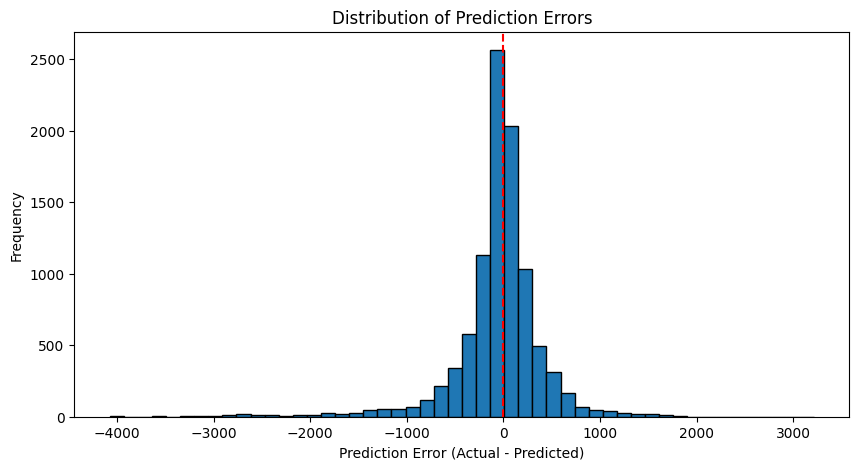

In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=50, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.show()


In [87]:
import time

start_time = time.time()

_ = rf_model.predict(X_test_final)

prediction_time = time.time() - start_time

print("Prediction time:", prediction_time)

Prediction time: 0.05494332313537598


In [88]:
print("Total prediction time:", round(prediction_time, 4), "seconds")

num_records = X_test_final.shape[0]

print("Number of test records:", num_records)

print(
    "Average time per prediction:",
    round((prediction_time / num_records) * 1000, 4),
    "milliseconds"
)

Total prediction time: 0.0549 seconds
Number of test records: 9638
Average time per prediction: 0.0057 milliseconds


In [89]:
print("Dataset memory usage:")
print(df_clean.memory_usage(deep=True).sum() / (1024 ** 2), "MB")

print("\nTraining data shape:", X_train_final.shape)
print("Testing data shape:", X_test_final.shape)

Dataset memory usage:
13.76849365234375 MB

Training data shape: (38549, 33)
Testing data shape: (9638, 33)


In [90]:
total_nodes = sum(
    tree.tree_.node_count for tree in rf_model.estimators_
)

print("Number of trees:", len(rf_model.estimators_))
print("Total nodes across all trees:", total_nodes)
print(
    "Average nodes per tree:",
    round(total_nodes / len(rf_model.estimators_), 2)
)

Number of trees: 100
Total nodes across all trees: 4362312
Average nodes per tree: 43623.12


### B1.1 Development of a Suitable Model and Implementation

A Random Forest Regressor was selected to predict traffic volume using the Metro Interstate Traffic Volume dataset. Random Forest is an ensemble learning algorithm that combines multiple decision trees to produce predictions. It was selected because it can model nonlinear relationships between traffic volume and different factors such as time, weather conditions and holidays.

**1. Feature selection and preprocessing**

The cleaned dataset was used for model development. The target variable was `traffic_volume`, while the input features included temperature, rainfall, snowfall, cloud coverage, holiday information, weather conditions and extracted time-based features.

The categorical features, `holiday` and `weather_main`, were converted into numerical representations using One-Hot Encoding. Numerical features were retained in their numerical form.

**2. Training and testing**

The dataset was divided chronologically into training and testing sets using an 80:20 split. This approach ensured that earlier observations were used for training and later observations were used for testing.

- Training records: 38,549
- Testing records: 9,638
- Features after encoding: 33

**3. Random Forest implementation**

A Random Forest Regressor was implemented using Scikit-learn with the following parameters:

- Number of decision trees (`n_estimators`): 100
- Random state: 42
- Parallel processing (`n_jobs`): -1

The model was trained using the training dataset and subsequently used to predict traffic volume for the unseen testing dataset.

**4. Baseline model**

A Dummy Regressor using the mean strategy was also implemented as a baseline. It predicts the average traffic volume from the training dataset for every test observation.

This baseline provided a reference point to determine whether the Random Forest model offered meaningful improvements over a simple average-based prediction approach.

### B1.2 Evaluation of Model Performance and Scalability

The performance of the Random Forest Regressor was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and the coefficient of determination (R²). The results were compared with the baseline Dummy Regressor.

**1. Model Performance Evaluation**

| Metric | Baseline Model | Random Forest |
|---|---:|---:|
| MAE | 1722.50 | 283.16 |
| MSE | 3871470.18 | 239509.33 |
| RMSE | 1967.61 | 489.40 |
| R² | Approximately 0 | 0.9381 |

The Random Forest model achieved an R² score of 0.9381, indicating that it explained approximately 93.81% of the variation in traffic volume on the test dataset.

Its MAE was approximately 283 vehicles, while its RMSE was approximately 489 vehicles. Both error measures were substantially lower than those of the baseline model, demonstrating that Random Forest provided considerably better predictions than a simple mean-based approach.

**2. Prediction Error Analysis**

The prediction error distribution showed that most predictions were concentrated around zero error. However, a small number of observations had considerably larger errors.

The model generally captured daily traffic patterns, although some large prediction errors occurred during periods when actual traffic volume was considerably lower than predicted. This indicates that the model performs well overall but may struggle with certain unusual traffic conditions.

**3. Scalability Evaluation**

The computational performance of the model was examined using dataset memory consumption, prediction time, feature matrix dimensions and model complexity.

| Parameter | Observed Result |
|---|---:|
| Dataset memory usage | 13.77 MB |
| Training records | 38,549 |
| Testing records | 9,638 |
| Number of decision trees | 100 |
| Total tree nodes | 4,362,312 |
| Prediction time | 0.2286 seconds |
| Average time per prediction | 0.0237 milliseconds |

The model generated predictions for 9,638 test observations in approximately 0.23 seconds. The average prediction time was approximately 0.0237 milliseconds per observation, demonstrating fast inference on the available dataset.

The dataset memory requirement of approximately 13.77 MB indicates that the data can be handled efficiently in the current computing environment. However, the total number of nodes across the 100 decision trees indicates considerable model complexity. Memory and computational requirements may increase with larger datasets or more complex model configurations.

**4. Limitations**

The dataset represents traffic observations from a single monitoring station on Interstate 94. Therefore, the results cannot directly establish the model's performance across an entire city.

Additionally, the evaluation was performed on a chronological holdout set. Further validation using different time periods and monitoring locations would be required before deploying the model in a real-world traffic management system. The scalability evaluation was limited to the available dataset and computing environment; large-scale distributed processing was not tested.

## C. Results and Conclusion

### C1.1 Results and Analysis

The developed Random Forest Regressor demonstrated strong performance in predicting traffic volume using historical traffic and weather-related information.

**1. Traffic pattern analysis**

Exploratory Data Analysis revealed clear variations in traffic volume throughout the day. Traffic was lowest during the early morning hours, particularly around 3 AM, and reached its highest average level around 4 PM.

Weekdays recorded higher average traffic volume than weekends. Friday had the highest average traffic among the days of the week, while Sunday recorded the lowest. Monthly analysis showed relatively higher average traffic during June and lower average traffic during December.

**2. Weather-related observations**

The analysis showed variations in average traffic volume across different weather conditions. However, the numerical correlation between individual weather variables and traffic volume was generally weak. This suggests that traffic volume is influenced by multiple factors rather than a single weather variable.

**3. Model results**

The Random Forest model achieved an R² score of 0.9381 and an MAE of approximately 283 vehicles on the testing dataset. It performed substantially better than the mean-based baseline model.

Feature importance analysis identified the hour of the day as the most influential feature, accounting for approximately 82.89% of the model's impurity-based feature importance. Day of the week and weekend status were also among the more influential features.

**4. Overall interpretation**

The results indicate that time-related patterns play an important role in predicting traffic volume in the selected dataset. Although the model achieved strong predictive performance, occasional large prediction errors highlight the need for further investigation and validation.

The findings are specific to the selected Interstate 94 monitoring station and should not be generalized to all urban roads without additional data.

The error analysis identified a few observations with large prediction errors, particularly when actual traffic volume was considerably lower than the predicted values. These cases suggest that the model may not fully capture unusual traffic conditions, highlighting the importance of further investigation and validation.

### C1.2 Conclusion

This project focused on analysing traffic patterns and predicting traffic volume using the Metro Interstate Traffic Volume dataset. The work involved data cleaning, preprocessing, feature engineering, exploratory data analysis and the implementation of a machine learning model.

A Random Forest Regressor was developed to predict traffic volume based on historical traffic patterns, time-related features and weather conditions. The model achieved an R² score of 0.9381, with a Mean Absolute Error of approximately 283 vehicles, demonstrating strong predictive performance on the testing dataset.

The analysis highlighted the importance of time-based features, particularly the hour of the day, in predicting traffic volume. The model also demonstrated fast prediction performance on the available dataset.

However, the study has certain limitations. The dataset represents only one monitoring station on Interstate 94, and the model has not been validated across multiple road networks. Further improvements could include incorporating data from additional traffic monitoring stations, testing other machine learning algorithms and performing additional validation.

Overall, the project demonstrates how data processing, exploratory analysis and machine learning can be combined to understand traffic patterns and develop traffic volume prediction models. Such approaches can support data-driven traffic analysis and contribute to better transportation planning.

### Benefits of the Assignment and Assessment of Course Learning Outcomes

The completion of this assignment provided practical experience in handling real-world datasets and applying data-processing techniques to a machine learning problem. It helped develop an understanding of data cleaning, feature engineering, exploratory data analysis, model development and performance evaluation.

The assignment also provided experience in using Python libraries such as Pandas, NumPy, Matplotlib and Scikit-learn to process data, generate visualisations and implement predictive models.

**Assessment of Course Learning Outcomes**

- **CO-1: Data quality and visualisation** – Achieved through identifying missing values, duplicate records and suspicious observations, cleaning the dataset and creating visualisations to understand traffic patterns.
- **CO-2: Data integration and transformation** – Partially addressed through combining the input features and target variable, handling categorical attributes, transforming data and extracting time-based features. Integration of multiple independent data sources was not implemented.
- **CO-3: Data processing frameworks and AI-driven scalable analysis** – Partially addressed through implementing a Random Forest model, evaluating its performance and examining its computational requirements. Large-scale distributed processing was not implemented.
- **CO-4: Data handling tools** – Achieved through practical use of Pandas, NumPy, Matplotlib, SciPy and Scikit-learn for data handling, analysis, visualisation and model evaluation.

Overall, the assignment helped connect theoretical concepts of data processing with practical implementation. It assessed the learning outcomes related to data quality, transformation, visualisation and machine learning, while providing an opportunity to understand the limitations of working with a single-source dataset.

## References

1. Hogue, J. (2019). *Metro Interstate Traffic Volume* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5X60B

2. Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32. https://doi.org/10.1023/A:1010933404324

3. Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

4. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.

5. Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2

6. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55